Улучшение орбит астероидов. Версия с весами и фильтрацией наблюдений

In [1]:
import astropy.constants as const
from astropy import units as u
from astropy.coordinates import SkyCoord,EarthLocation, GCRS, ICRS
from astropy.time import Time
from astroquery.jplsbdb import SBDB
from astroquery.mpc import MPC

import pandas as pd

import ctypes
import os

import matplotlib.pyplot as plt
from brokenaxes import brokenaxes 
%matplotlib widget

import warnings
warnings.filterwarnings('ignore')

In [2]:
import assist

from astroquery.mpc import MPC
from astroquery.jplhorizons import Horizons

import rebound

from math import *
import numpy as np
import pandas as pd

from scipy.optimize import dual_annealing
from scipy.optimize import minimize
from scipy.optimize import least_squares
from scipy.optimize import curve_fit

au_to_d = (1*u.au/const.c.to('au/s')).to('d').value
ephem_dir = os.path.expanduser("~/.assist")
ephem = assist.Ephem(os.path.join(ephem_dir, "linux_p1550p2650.440"), os.path.join(ephem_dir, "sb441-n16.bsp"))

def cart2radec(x,y,z):
#     transformation x,y,z -> ra,dec
    r = sqrt(x**2+y**2+z**2)
    R = sqrt(x**2+y**2)
    dec = atan2(z/r,R/r)
    ra = atan2(y/R,x/R)
    if ra<0:
        ra+=2*pi
    return ra,dec

def phase_angle(X,Y,Z,x,y,z):
    D = sqrt(X*X+Y*Y+Z*Z)
    d = sqrt(x*x+y*y+z*z)
    return degrees(acos((X*x+Y*y+Z*z)/D/d))

import pandas as pd


In [3]:
# астероид
ast_id = '433'
# ast_id ='2010 XC15'
# ast_id ='2014 HK129'
# данные MPC
df_mpc = pd.read_csv('res_amp_mpc_%s.csv'%ast_id.replace(' ','_'))
df_mpc

,ast_id,MPC,Vmag,JD,RA,DEC,e_RA,e_DEC,OMC_RA,OMC_DEC,OMC/err
0,433,532,11.433,2.414528e+06,317.612708,-5.887083,0.804097,0.319501,4.900021,-0.084212,5.662040
1,433,532,11.454,2.414529e+06,317.206354,-5.889056,1.964903,0.207999,2.485815,-0.560372,1.289566
2,433,532,11.736,2.414541e+06,313.080865,-5.952396,0.862652,0.365276,3.274752,-0.201070,3.501429
3,433,532,11.784,2.414543e+06,312.554677,-5.964917,1.539607,0.330576,3.283635,-0.564063,2.115618
4,433,708,12.719,2.414589e+06,313.996042,-5.011924,1.354804,1.060210,3.950866,2.110935,2.603759
...,...,...,...,...,...,...,...,...,...,...,...
924,433,C40,12.900,2.460249e+06,312.815299,-6.330358,0.035424,0.018924,-0.040887,0.079647,2.203527
925,433,G02,11.262,2.460171e+06,318.907115,-8.455264,0.039682,0.092130,0.016320,0.093989,0.946095
926,433,G02,12.949,2.460253e+06,314.098403,-6.006046,0.004720,0.020507,0.009947,0.157331,7.210169
927,433,G02,12.995,2.460257e+06,315.484792,-5.647600,0.024997,0.010363,-0.029854,-0.072001,2.819086


In [4]:
# добавляем наши наблюдения
df = pd.read_csv('res_amp_%s.csv'%ast_id.replace(' ','_'))
df

,ast_id,MPC,Vmag,JD,RA,DEC,e_RA,e_DEC,OMC_RA,OMC_DEC,OMC/err
0,433,84,0,2.415254e+06,33.656217,30.485345,0.136528,0.027230,-0.070562,-0.379378,2.771817
1,433,84,0,2.415254e+06,33.673898,30.503992,0.171417,0.088355,-0.128908,-0.316431,1.771763
2,433,84,0,2.426283e+06,112.641861,47.644218,0.234475,0.300393,0.173068,-0.149510,0.600161
3,433,84,0,2.426283e+06,112.638564,47.644274,0.103821,0.093870,0.301297,0.013445,2.154793
4,433,84,0,2.426283e+06,112.633794,47.644258,0.174748,0.086395,0.105666,-0.078790,0.676148
5,433,84,0,2.426283e+06,112.619116,47.644291,0.098454,0.079352,0.256242,0.002173,2.026480
6,433,84,0,2.426316e+06,142.572520,41.948063,0.277874,0.179992,-0.053677,-0.350818,1.071964
7,433,84,0,2.426316e+06,142.571270,41.948702,0.207902,0.111398,-0.079641,-0.352514,1.532216
8,433,84,0,2.426316e+06,142.569760,41.949562,0.240117,0.165008,-0.135098,-0.028585,0.473965
9,433,84,0,2.426316e+06,142.568473,41.950229,0.177923,0.192767,0.060586,-0.184080,0.738747


In [5]:
# данные из SBDB
# ep = Time(mpc_data[0]['epoch'],format='jd')
# ep.value
# ep_orb = Time(ep, format='jd').tdb.jd
sbdb = SBDB.query(ast_id, phys = True, radar = True)
ep_orb = sbdb['orbit']['epoch'].value
ep_orb = Time(ep_orb, format='jd').tdb.jd
# эпоха, для которой правильнее всего брать вектор состояния (из базы данных SBDB)
ep_orb

np.float64(2461200.500800749)

In [6]:
# вектор состояния
obj = Horizons(id=ast_id, id_type='smallbody', location='@0', epochs=ep_orb)
pos_ast = obj.vectors(refplane='earth')
state_vector = np.array([pos_ast['x'][0], pos_ast['y'][0],pos_ast['z'][0],pos_ast['vx'][0],pos_ast['vy'][0],pos_ast['vz'][0]])

In [7]:
# формируем исходные данные для вычислений
# и считаем вектор положений наблюдателя на все моменты времени, чтобы не пересчитывать каждый раз при улучшении орбиты

sim = rebound.Simulation() 
sim.t = ep_orb - ephem.jd_ref

x,y,z,vx,vy,vz = state_vector

sim.add(x=x,y=y,z=z,vx=vx,vy=vy,vz=vz)
ex = assist.Extras(sim, ephem)

ra_mpc,dec_mpc,jd = np.array([]),np.array([]),np.array([])
e_ra,e_dec,snr = np.array([]),np.array([]),np.array([])
x_o,y_o,z_o = np.array([]),np.array([]),np.array([])
is_pulkovo_data = []

yr = np.array([])

omc_max = 2.0

# данные mpc
for i,row in df_mpc.iterrows():
    ep = Time(row['JD'],format='jd')
    ep_tdb = ep.tdb.jd
    try:
        mpc_loc = MPC.get_observatory_location(str(row['MPC']))
    
        obs_loc = EarthLocation.from_geocentric(
                mpc_loc[1]*const.R_earth*cos(mpc_loc[0].radian),
                mpc_loc[1]*const.R_earth*sin(mpc_loc[0].radian),
                mpc_loc[2]*const.R_earth)
        # pos_o, vel_o = obs_loc.get_gcrs_posvel(Time(ep_tdb,format='jd',scale='tdb'))
        pos_o, vel_o = obs_loc.get_gcrs_posvel(ep)
        X_o = pos_o.x.to('au').value; Y_o = pos_o.y.to('au').value; Z_o = pos_o.z.to('au').value
    except Exception:
        print(mpc_loc)
        continue
    ex.integrate_or_interpolate(ep_tdb - ephem.jd_ref)
    x_e,y_e,z_e = ephem.get_particle("earth", ep_tdb - ephem.jd_ref).xyz
    
    if sqrt(row['OMC_RA']**2+row['OMC_DEC']**2)>omc_max:
        continue
    
    x_o,y_o,z_o = np.append(x_o,x_e+X_o),np.append(y_o,y_e+Y_o),np.append(z_o,z_e+Z_o)
    
    jd = np.append(jd, ep_tdb)
    yr = np.append(yr, ep.copy(format='jyear').value)
    ra_mpc,dec_mpc = np.append(ra_mpc,row['RA']),np.append(dec_mpc,row['DEC'])
    e_ra,e_dec = np.append(e_ra,row['e_RA']),np.append(e_dec,row['e_DEC'])
    snr = np.append(snr,row['OMC/err'])
    is_pulkovo_data.append(False)
print('Pulkovo data')
# наши данные
for i,row in df.iterrows():
    ep = Time(row['JD'],format='jd')
    ep_tdb = ep.tdb.jd
    try:
        mpc_code = '%03d'%row['MPC']
    except Exception:
        mpc_code = row['MPC']
    # try:
    mpc_loc = MPC.get_observatory_location(mpc_code)

    obs_loc = EarthLocation.from_geocentric(
            mpc_loc[1]*const.R_earth*cos(mpc_loc[0].radian),
            mpc_loc[1]*const.R_earth*sin(mpc_loc[0].radian),
            mpc_loc[2]*const.R_earth)
    # pos_o, vel_o = obs_loc.get_gcrs_posvel(Time(ep_tdb,format='jd',scale='tdb'))
    pos_o, vel_o = obs_loc.get_gcrs_posvel(ep)
    X_o = pos_o.x.to('au').value; Y_o = pos_o.y.to('au').value; Z_o = pos_o.z.to('au').value
    # except Exception:
    #     print(mpc_loc)
    #     continue
    ex.integrate_or_interpolate(ep_tdb - ephem.jd_ref)
    x_e,y_e,z_e = ephem.get_particle("earth", ep_tdb - ephem.jd_ref).xyz
    if sqrt(row['OMC_RA']**2+row['OMC_DEC']**2)>omc_max:
        continue
    print('Pulkovo data added')
    x_o,y_o,z_o = np.append(x_o,x_e+X_o),np.append(y_o,y_e+Y_o),np.append(z_o,z_e+Z_o)
    
    jd = np.append(jd, ep_tdb)
    yr = np.append(yr, ep.copy(format='jyear').value)
    ra_mpc,dec_mpc = np.append(ra_mpc,row['RA']),np.append(dec_mpc,row['DEC'])
    e_ra,e_dec = np.append(e_ra,row['e_RA']),np.append(e_dec,row['e_DEC'])
    snr = np.append(snr,row['OMC/err'])
    is_pulkovo_data.append(True)

Pulkovo data
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added
Pulkovo data added


In [8]:
def ast_eph(p):
    x,y,z,vx,vy,vz,A2 = p
    sim = rebound.Simulation() 
    sim.t = ep_orb - ephem.jd_ref
    sim.add(x=x,y=y,z=z,vx=vx,vy=vy,vz=vz)
    ex = assist.Extras(sim, ephem)
    ex.particle_params = np.array([0.0, A2, 0.0])
    # ex.particle_params = np.array([0.0, 0.0, 0.0])
    
    Npos = np.size(jd)
    ra,dec = np.zeros(Npos),np.zeros(Npos)
    for k in range(Npos):
        delta_t = 0
        while True:
            tau  = jd[k] - ephem.jd_ref
            ex.integrate_or_interpolate(tau - delta_t)
            x,y,z = sim.particles[0].x,sim.particles[0].y,sim.particles[0].z
            X,Y,Z = x - x_o[k],y - y_o[k],z - z_o[k]
            if fabs(sqrt(X**2+Y**2+Z**2)*au_to_d - delta_t)<1e-7:
                break
            else:
                delta_t = sqrt(X**2+Y**2+Z**2)*au_to_d
        ra[k],dec[k]=np.degrees(cart2radec(X,Y,Z))
    return ra,dec

def ast_eph2(ep,*p):
    x,y,z,vx,vy,vz,A2 = p
    sim = rebound.Simulation() 
    sim.t = ep_orb - ephem.jd_ref
    sim.add(x=x,y=y,z=z,vx=vx,vy=vy,vz=vz)
    ex = assist.Extras(sim, ephem)
    ex.particle_params = np.array([0.0, A2, 0.0])
    # ex.particle_params = np.array([0.0, 0.0, 0.0])
    
    Npos = np.size(jd)
    ra,dec = np.zeros(Npos),np.zeros(Npos)
    for k in range(Npos):
        delta_t = 0
        while True:
            tau  = jd[k] - ephem.jd_ref
            ex.integrate_or_interpolate(tau - delta_t)
            x,y,z = sim.particles[0].x,sim.particles[0].y,sim.particles[0].z
            X,Y,Z = x - x_o[k],y - y_o[k],z - z_o[k]
            if fabs(sqrt(X**2+Y**2+Z**2)*au_to_d - delta_t)<1e-7:
                break
            else:
                delta_t = sqrt(X**2+Y**2+Z**2)*au_to_d
        ra[k],dec[k]=np.degrees(cart2radec(X,Y,Z))
    return np.hstack((ra,dec))

def ast_eph_f(ep,*p):
    x,y,z,vx,vy,vz,A1,A2,A3 = p
    sim = rebound.Simulation() 
    sim.t = ep_orb - ephem.jd_ref
    sim.add(x=x,y=y,z=z,vx=vx,vy=vy,vz=vz)
    ex = assist.Extras(sim, ephem)
    ex.particle_params = np.array([A1, A2, A3])
    # ex.particle_params = np.array([0.0, 0.0, 0.0])
    
    Npos = np.size(jd)
    ra,dec = np.zeros(Npos),np.zeros(Npos)
    for k in range(Npos):
        delta_t = 0
        while True:
            tau  = jd[k] - ephem.jd_ref
            ex.integrate_or_interpolate(tau - delta_t)
            x,y,z = sim.particles[0].x,sim.particles[0].y,sim.particles[0].z
            X,Y,Z = x - x_o[k],y - y_o[k],z - z_o[k]
            if fabs(sqrt(X**2+Y**2+Z**2)*au_to_d - delta_t)<1e-7:
                break
            else:
                delta_t = sqrt(X**2+Y**2+Z**2)*au_to_d
        ra[k],dec[k]=np.degrees(cart2radec(X,Y,Z))
    return np.hstack((ra,dec))

In [9]:
delta_A2 = 1E-12
ast_state_A2 = np.append(state_vector,0)
print(ast_state_A2)
x,y,z,vx,vy,vz,A2 = ast_state_A2
delta_x=delta_y=delta_z = 1e-4
delta_vx=delta_vy=delta_vz = 1e-3
lw = [x-delta_x,y-delta_y,z-delta_z,vx-delta_vx,vy-delta_vy,vz-delta_vz,-delta_A2]# нижняя граница 
up = [x+delta_x,y+delta_y,z+delta_z,vx+delta_vx,vy+delta_vy,vz+delta_vz,delta_A2]# верхняя граница 

[-1.1609533  -0.53566743 -0.51280918  0.00483106 -0.01279928 -0.00639543
  0.        ]


In [10]:
np.size(snr)

900

In [11]:
# оптимизация нелинейным МНК по методу Левенберга-Марквардта
p,pcov = curve_fit(f=ast_eph2, p0=np.append(state_vector,0),
                   # sigma = np.hstack((e_ra**2,e_dec**2)),
                   sigma = np.hstack((np.sqrt(snr**2+e_ra**2),np.sqrt(snr**2+e_dec**2))),
                   # sigma = np.hstack((np.sqrt(snr**2+e_ra**2)/(2026-yr),np.sqrt(snr**2+e_dec**2)/(2026-yr))),
                xdata = np.hstack((jd,jd)),ydata=np.hstack((ra_mpc,dec_mpc)), bounds=(lw,up))

In [12]:

ra_eph,dec_eph = ast_eph(p)
# unit weight error
3600*sqrt(np.std(ra_mpc - ra_eph)**2+ np.std(dec_mpc - dec_eph)**2)

0.5596011729770066

In [14]:
# A2, A2 standard error
p[6],sqrt(pcov[6,6])

(np.float64(6.042974809184716e-16), 1.463141913583436e-16)

In [15]:
# это без оптимизации
ra_src,dec_src = ast_eph(np.append(state_vector,0))#-147.3E-15
3600*sqrt(np.std(ra_mpc - ra_src)**2+ np.std(dec_mpc - dec_src)**2)

0.5660122717982129

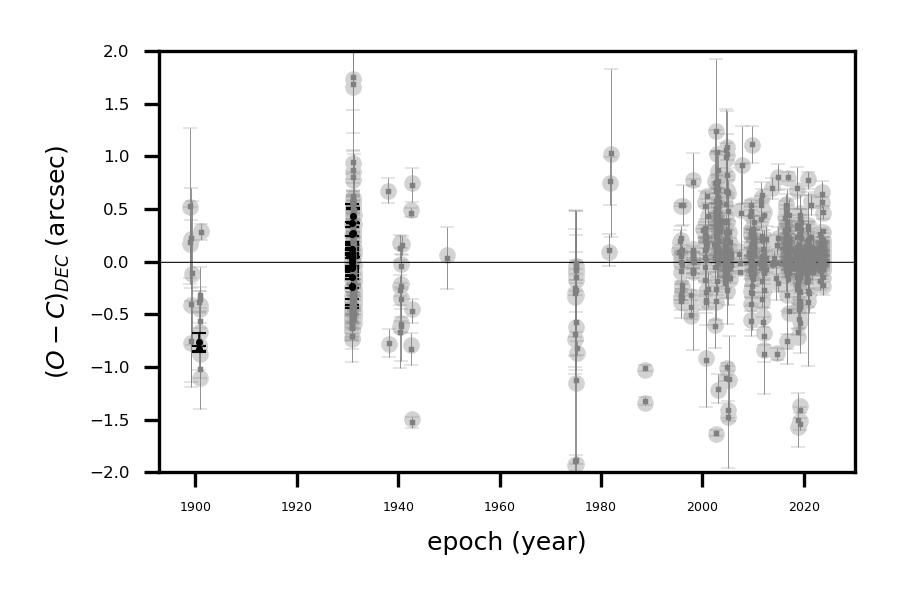

In [16]:
# print(yr[list(~np.array(is_pulkovo_data))])
# yr
fig,ax = plt.subplots(figsize=(3, 2), dpi=300)
ax.errorbar(yr[list(~np.array(is_pulkovo_data))], 3600*(dec_mpc-dec_eph)[list(~np.array(is_pulkovo_data))], yerr=e_dec[list(~np.array(is_pulkovo_data))], fmt='s',capsize=1.6, elinewidth=0.2,
            markeredgewidth=0.1, 
            linewidth=0.1, color='grey', markersize=1.2)

ax.errorbar(yr[is_pulkovo_data], 3600*(dec_mpc-dec_eph)[is_pulkovo_data], yerr=e_dec[is_pulkovo_data], fmt='o',capsize=1.6, elinewidth=0.4,
            markeredgewidth=0.5, 
            linewidth=0.2, color='black', markersize=1.2)

ax.scatter(yr,3600*(dec_mpc-dec_src),  c='lightgrey',  s=16, linewidths=0.0)
# ax.scatter(yr,3600*(dec_mpc-dec_eph),  c='black',  s=2, linewidths=0.0)
plt.axhline(y = 0, color = 'black', linestyle = '-', linewidth=0.1)
ax.set_xlabel('epoch (year)', fontsize = 6)
ax.set_ylabel('$(O-C)_{DEC}$ (arcsec)', fontsize = 6)
ax.set_ylim(-2,2)
ax.tick_params(axis='x', which='major', labelsize=3)
ax.tick_params(axis='x', which='minor', labelsize=3)
ax.tick_params(axis='y', which='major', labelsize=4)
ax.tick_params(axis='y', which='minor', labelsize=4)
# ax.ticklabel_format(useOffset=False)
ax.axhline(y = 0, color = 'k', linestyle = '-', linewidth=0.2)
plt.tight_layout()


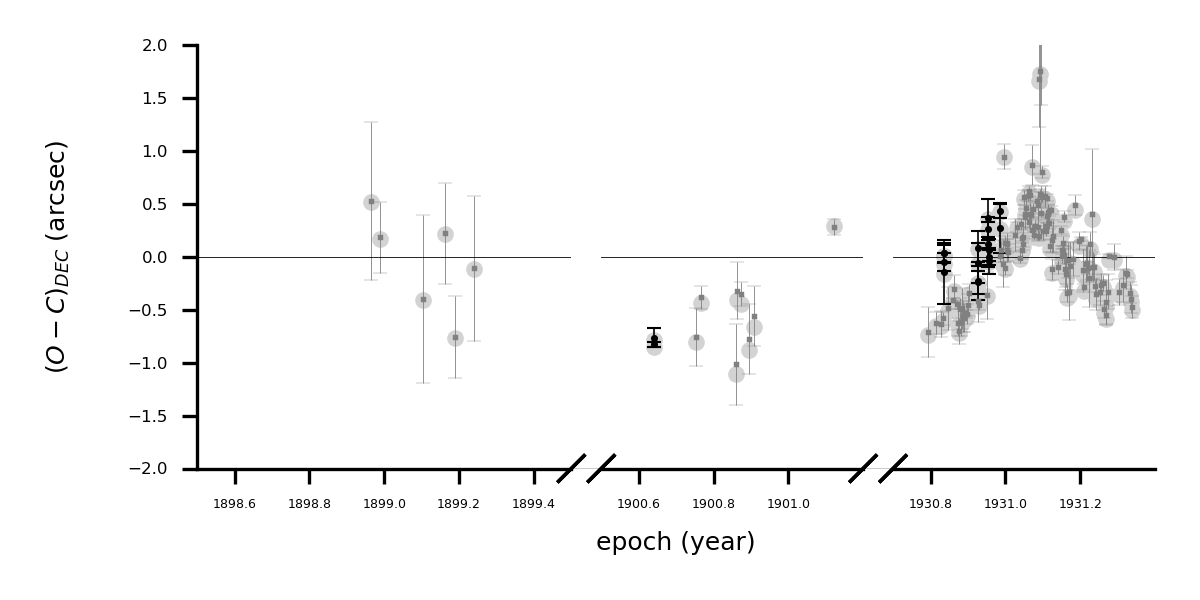

In [17]:
# fig,ax = plt.subplots(1,figsize=(2.8, 2.0), dpi=300)
fig = plt.figure(figsize=(4.0, 2.0), dpi=300)

# ax = brokenaxes(xlims=((2010.9,2011.0),(2012.85,2012.95),(2015.85,2015.9),(2022.85,2023.05)),  wspace=0.1) 
# ax = brokenaxes(xlims=((2014.3,2014.5),(2022.7,2023.0)),  wspace=0.1) 
# ax = brokenaxes(xlims=((1896,1904),(1928,1933),(1940,1950),(1970,1985),(1990,2025)),  wspace=0.1) 
ax = brokenaxes(xlims=((1898.5,1899.5),(1900.5,1901.2),(1930.7,1931.4)),  wspace=0.1) 


ax.errorbar(yr[list(~np.array(is_pulkovo_data))], 3600*(dec_mpc-dec_eph)[list(~np.array(is_pulkovo_data))], yerr=e_dec[list(~np.array(is_pulkovo_data))], fmt='s',capsize=1.6, elinewidth=0.2,
            markeredgewidth=0.1, 
            linewidth=0.1, color='grey', markersize=1.2)

ax.errorbar(yr[is_pulkovo_data], 3600*(dec_mpc-dec_eph)[is_pulkovo_data], yerr=e_dec[is_pulkovo_data], fmt='o',capsize=1.6, elinewidth=0.4,
            markeredgewidth=0.5, 
            linewidth=0.2, color='black', markersize=1.2)

ax.scatter(yr,3600*(dec_mpc-dec_src),  c='lightgrey',  s=16, linewidths=0.0)
# ax.scatter(yr,3600*(dec_mpc-dec_eph),  c='black',  s=2, linewidths=0.0)
plt.axhline(y = 0, color = 'black', linestyle = '-', linewidth=0.1)
ax.set_xlabel('epoch (year)', fontsize = 6)
ax.set_ylabel('$(O-C)_{DEC}$ (arcsec)', fontsize = 6)
ax.set_ylim(-2,2)
ax.tick_params(axis='x', which='major', labelsize=3)
ax.tick_params(axis='x', which='minor', labelsize=3)
ax.tick_params(axis='y', which='major', labelsize=4)
ax.tick_params(axis='y', which='minor', labelsize=4)
ax.ticklabel_format(useOffset=False)
ax.axhline(y = 0, color = 'k', linestyle = '-', linewidth=0.2)
plt.tight_layout()
for handle in ax.diag_handles:
    handle.remove()
    ax.draw_diags()

# plt.tight_layout()
plt.savefig('omc_dec_%s.png'%ast_id.replace(' ','_'))

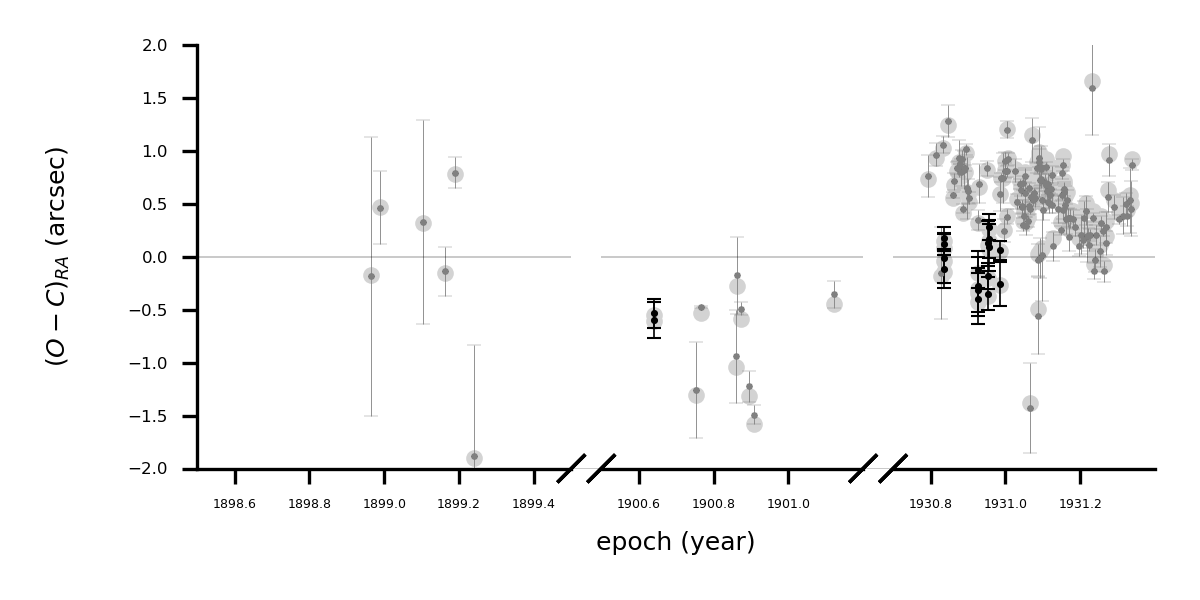

In [18]:
# fig,ax = plt.subplots(1,figsize=(2.8, 2.0), dpi=300)
fig = plt.figure(figsize=(4.0, 2.0), dpi=300)

# ax = brokenaxes(xlims=((2010.9,2011.0),(2012.85,2012.95),(2015.85,2015.9),(2022.85,2023.05)),  wspace=0.1) 
# ax = brokenaxes(xlims=((2014.3,2014.5),(2022.7,2023.0)),  wspace=0.1) 
ax = brokenaxes(xlims=((1898.5,1899.5),(1900.5,1901.2),(1930.7,1931.4)),  wspace=0.1) 

ax.errorbar(yr[list(~np.array(is_pulkovo_data))], 3600*(ra_mpc-ra_eph)[list(~np.array(is_pulkovo_data))], yerr=e_ra[list(~np.array(is_pulkovo_data))], fmt='s',capsize=1.6, elinewidth=0.2,
            markeredgewidth=0.1, 
            linewidth=0.1, color='grey', markersize=1.2)

ax.errorbar(yr[is_pulkovo_data], 3600*(ra_mpc-ra_eph)[is_pulkovo_data], yerr=e_ra[is_pulkovo_data], fmt='o',capsize=1.6, elinewidth=0.4,
            markeredgewidth=0.5, 
            linewidth=0.2, color='black', markersize=1.2)

ax.scatter(yr,3600*(ra_mpc-ra_src),  c='lightgrey',  s=16, linewidths=0.0)
ax.scatter(yr,3600*(ra_mpc-ra_eph),  c='black',  s=2, linewidths=0.0)
plt.axhline(y = 0, color = 'black', linestyle = '-', linewidth=0.1)
ax.set_xlabel('epoch (year)', fontsize = 6)
ax.set_ylabel('$(O-C)_{RA}$ (arcsec)', fontsize = 6)
ax.set_ylim(-2.0,2.0)
ax.tick_params(axis='x', which='major', labelsize=3)
ax.tick_params(axis='x', which='minor', labelsize=3)
ax.tick_params(axis='y', which='major', labelsize=4)
ax.tick_params(axis='y', which='minor', labelsize=4)
ax.ticklabel_format(useOffset=False)
ax.axhline(y = 0, color = 'k', linestyle = '-', linewidth=0.1)
plt.tight_layout()
for handle in ax.diag_handles:
    handle.remove()
    ax.draw_diags()
    
plt.savefig('omc_ra_%s.png'%ast_id.replace(' ','_'))

# plt.tight_layout()